**420-C74-SF - Techniques d'apprentissage automatique - Automne 2026 - Spécialiste en solutions d'intelligence artificielle**<br/>
© 2026 MKL.AI - Tous droits réservés
<br/>
![Atelier - Évaluation des modèles de classification](static/17-A-banner.png)
<br/>
**Objectif:** cette séance de travaux pratiques a pour objectif la mise en oeuvre des différentes techniques d'évaluation des modèles de classifications sur des données débalancées

In [1]:
%reload_ext autoreload
%autoreload 2
%matplotlib inline

### 1 - Simulation de données

In [2]:
from sklearn.datasets import make_moons
from imblearn.datasets import make_imbalance

In [3]:
N = 10000
ratio_debalancement = 0.01

X_raw, y_raw = make_moons(n_samples=10*N, shuffle=True, noise=0.3, random_state=2020)
X, y =  make_imbalance(X_raw, y_raw, sampling_strategy={0: int(N*(1-ratio_debalancement)), 1: int(N*(ratio_debalancement))})

#### Affichage du jeu de données simulé (classes balancées)

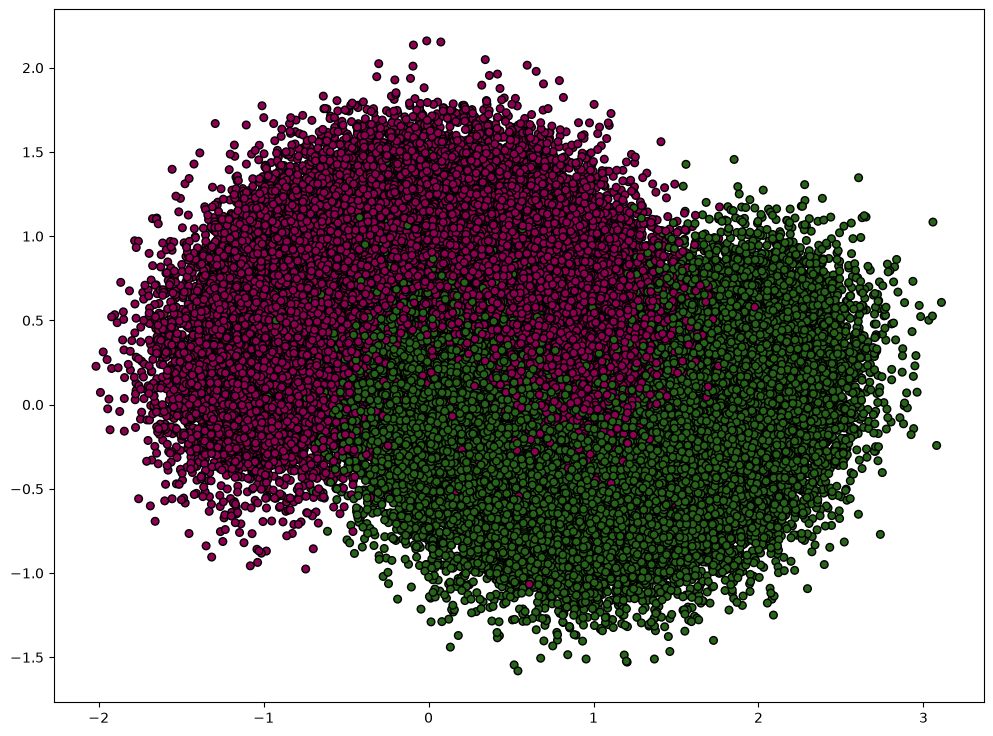

In [4]:
import matplotlib.pyplot as plt

fig = plt.figure(1, figsize=(12, 9))
plt.scatter(X_raw[:, 0], X_raw[:, 1], c=y_raw, cmap='PiYG', edgecolor='k', s=30)
plt.show()

#### Affichage du jeu de données simulé (classes fortement débalancées)

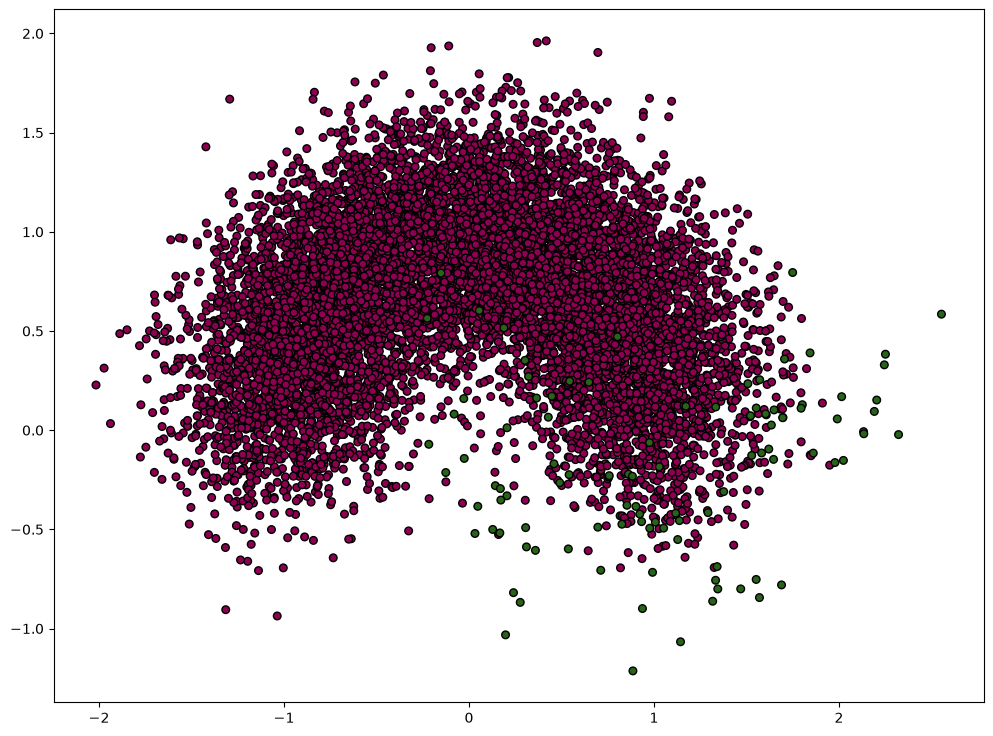

In [5]:
fig = plt.figure(1, figsize=(12, 9))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='PiYG', edgecolor='k', s=30)
plt.show()

### 2 - Préparation de données

<strong>
Séparation des données en train (40%), validation (30%) et test (30%)
</strong>

In [6]:
import numpy as np
from sklearn.model_selection import train_test_split

# 40% train, 60% restant séparé en deux parts égales (30% val, 30% test)
# stratify=y pour conserver la même proportion de la classe minoritaire dans chaque ensemble
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, train_size=0.4, stratify=y, random_state=2020)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=2020)

print(f'Train: {X_train.shape[0]} observations, {y_train.sum()} positifs')
print(f'Val: {X_val.shape[0]} observations, {y_val.sum()} positifs')
print(f'Test: {X_test.shape[0]} observations, {y_test.sum()} positifs')

Train: 4000 observations, 40 positifs
Val: 3000 observations, 30 positifs
Test: 3000 observations, 30 positifs


### 3 - Modèle de référence (baseline)

#### Création d'un modèle baseline et calcul de sa précision (accuracy)

In [7]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

# Le modèle baseline prédit toujours la classe majoritaire
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)

print(f'Accuracy baseline (val) = {accuracy_score(y_val, baseline.predict(X_val)):.4f}')
# Environ 99% d'accuracy sans jamais détecter un seul positif: l'accuracy n'est pas une bonne métrique ici !

Accuracy baseline (val) = 0.9900


### 4 - Entraînement d'un classificateur (régression logistique, ordre 3)

#### Entraînement du modèle et choix du paramètre de régularisation

In [8]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

poly = PolynomialFeatures(degree=3)
X_train_poly = poly.fit_transform(X_train)
X_val_poly = poly.transform(X_val)

# Choix de C (inverse de la force de régularisation) selon l'AUC sur l'ensemble de validation
Cs = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
auc_val = []
for C in Cs:
    clf = LogisticRegression(C=C, max_iter=10000)
    clf.fit(X_train_poly, y_train)
    auc_val.append(roc_auc_score(y_val, clf.predict_proba(X_val_poly)[:,1]))
    print(f'C = {C:<8} AUC val = {auc_val[-1]:.4f}')

best_C = Cs[int(np.argmax(auc_val))]
print(f'Meilleur C = {best_C}')

logreg = LogisticRegression(C=best_C, max_iter=10000)
logreg.fit(X_train_poly, y_train)

C = 0.001    AUC val = 0.8788
C = 0.01     AUC val = 0.9119
C = 0.1      AUC val = 0.9648
C = 1        AUC val = 0.9797
C = 10       AUC val = 0.9811
C = 100      AUC val = 0.9815
C = 1000     AUC val = 0.9815
Meilleur C = 1000


,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1000
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",10000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is

#### Affichage de la frontière de décision

([], [])

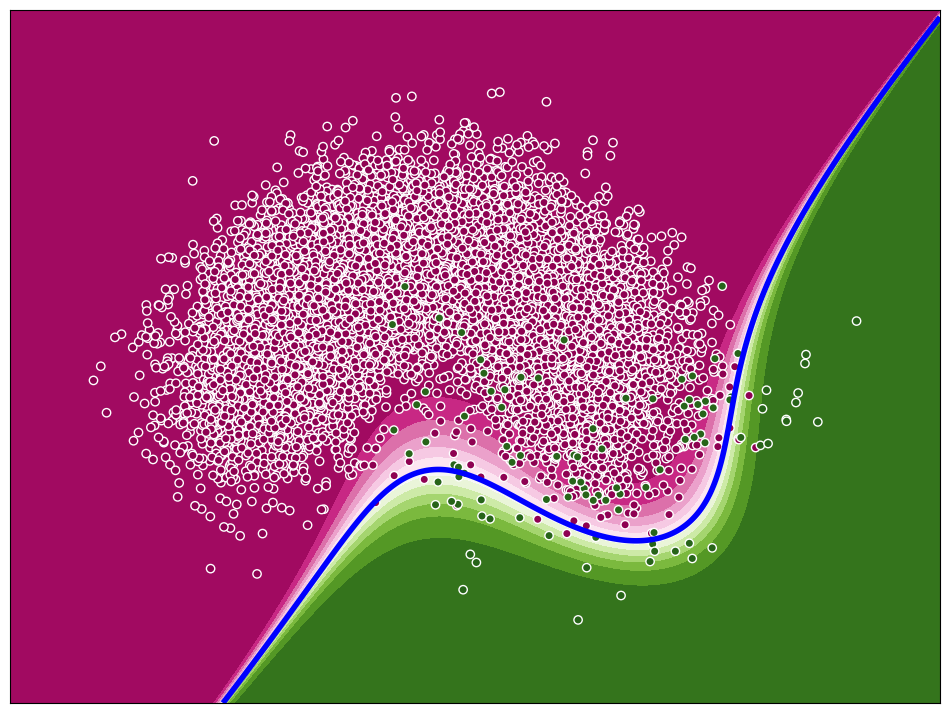

In [9]:
x_min, x_max = X[:, 0].min() - .5, X[:, 0].max() + .5
y_min, y_max = X[:, 1].min() - .5, X[:, 1].max() + .5
h = .01  # step size in the mesh
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

CC = np.c_[xx.ravel(), yy.ravel()]
Z = logreg.predict_proba(poly.fit_transform(CC))[:,1].reshape(xx.shape)

fig = plt.figure(2, figsize=(12, 9))

plt.contourf(xx, yy, Z, cmap="PiYG", levels=15)
plt.contour(xx, yy, Z, [0.5], colors=["b"], linewidths=[4])

plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='w', cmap='PiYG', linewidth=1)
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())
plt.xticks(())
plt.yticks(())

### 5 - Matrice de confusion sur l'ensemble de validation

#### Affichage de la matrice de confusion pour un seuil de classification rigide de 0.5. Utiliser le fichiers helpers.py

Confusion matrix, without normalization


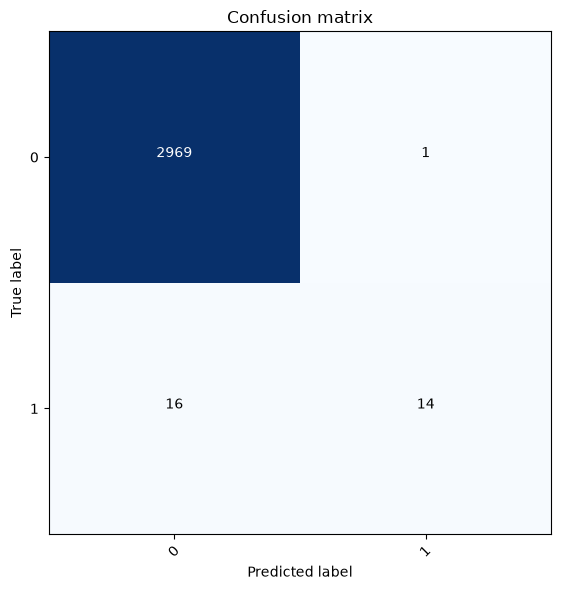

In [10]:
from sklearn.metrics import confusion_matrix
from helpers import plot_confusion_matrix

y_val_pred_proba = logreg.predict_proba(X_val_poly)[:,1]
y_val_pred = (y_val_pred_proba >= 0.5).astype(int)

cm = confusion_matrix(y_val, y_val_pred)

fig = plt.figure(3, figsize=(6, 6))
plot_confusion_matrix(cm, classes=['0', '1'])
plt.show()

#### Calcul de la précision sur l'ensemble de validation

In [11]:
from sklearn.metrics import precision_score, recall_score

print(f'Accuracy (val) = {accuracy_score(y_val, y_val_pred):.4f}')
print(f'Précision (val) = {precision_score(y_val, y_val_pred, zero_division=0):.4f}')
print(f'Rappel (val) = {recall_score(y_val, y_val_pred):.4f}')

Accuracy (val) = 0.9943
Précision (val) = 0.9333
Rappel (val) = 0.4667


### 6 - Courbe ROC et l'AUC

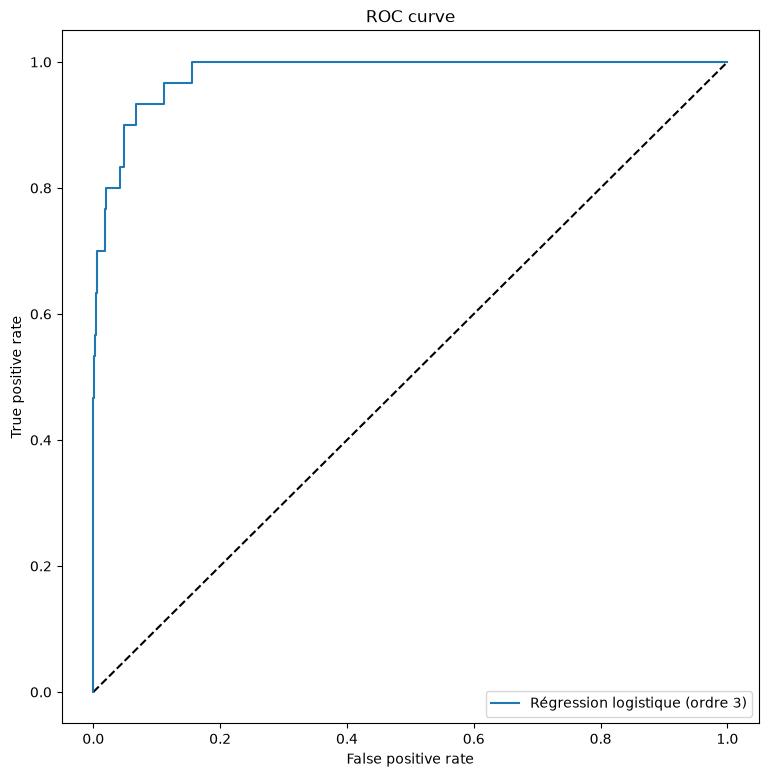

In [12]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_val, y_val_pred_proba)

fig = plt.figure(4, figsize=(9, 9))
plt.plot([0, 1], [0, 1], 'k--')
plt.plot(fpr, tpr, label='Régression logistique (ordre 3)')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curve')
plt.legend()
plt.show()

#### Calcul de la précision sur l'ensemble de validation

In [13]:
# AUC sur l'ensemble de validation
print(f'AUC (val) = {roc_auc_score(y_val, y_val_pred_proba):.4f}')

AUC (val) = 0.9815


#### Sélection de la meilleur valeur du seuil

Seuil sélectionné = 0.0175 (TPR = 0.933, FPR = 0.067)
Confusion matrix, without normalization


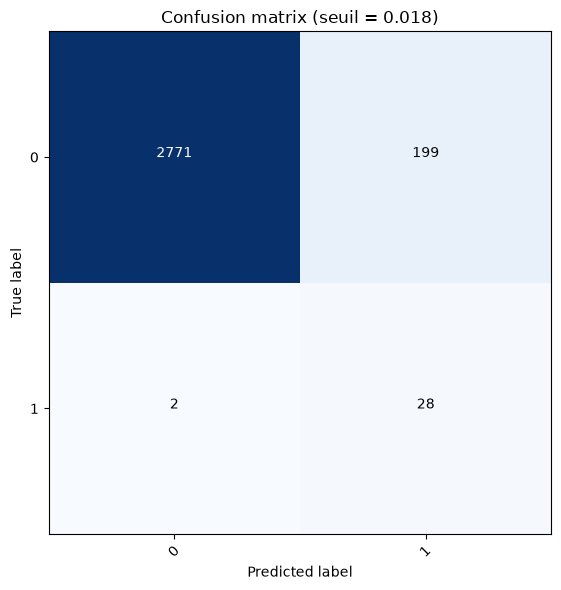

Accuracy (val) = 0.9330
Précision (val) = 0.1233
Rappel (val) = 0.9333


In [14]:
# Indice de Youden: seuil qui maximise TPR - FPR
best_idx = np.argmax(tpr - fpr)
selected_threshold = thresholds[best_idx]
print(f'Seuil sélectionné = {selected_threshold:.4f} (TPR = {tpr[best_idx]:.3f}, FPR = {fpr[best_idx]:.3f})')

y_val_pred_selected = (y_val_pred_proba >= selected_threshold).astype(int)
cm_selected = confusion_matrix(y_val, y_val_pred_selected)

fig = plt.figure(figsize=(6, 6))
plot_confusion_matrix(cm_selected, classes=['0', '1'], title=f'Confusion matrix (seuil = {selected_threshold:.3f})')
plt.show()

print(f'Accuracy (val) = {accuracy_score(y_val, y_val_pred_selected):.4f}')
print(f'Précision (val) = {precision_score(y_val, y_val_pred_selected):.4f}')
print(f'Rappel (val) = {recall_score(y_val, y_val_pred_selected):.4f}')

#### Affichage de la frontière de décision

([], [])

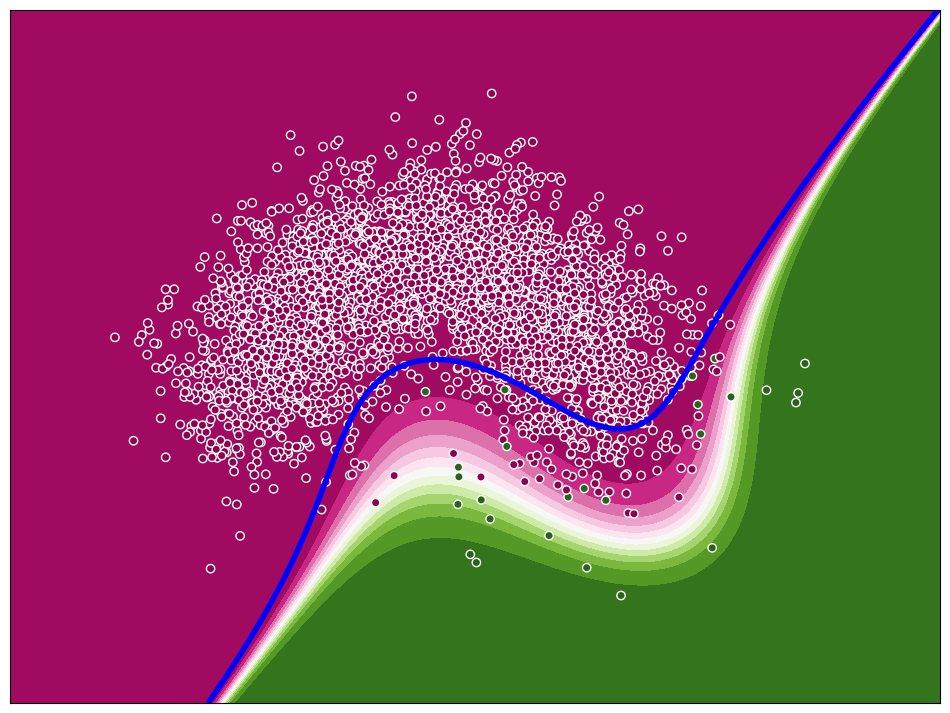

In [15]:
fig = plt.figure(5, figsize=(12, 9))

plt.contourf(xx, yy, Z, cmap="PiYG", levels=15)
plt.contour(xx, yy, Z, [selected_threshold], colors=["b"], linewidths=[4])

plt.scatter(X_val[:, 0], X_val[:, 1], c=y_val, edgecolors='w', cmap='PiYG', linewidth=1)

plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())
plt.xticks(())
plt.yticks(())

### 7 -  Calculer la courbe de précision/rappel

#### Affichage de la courbe de précision et rappel

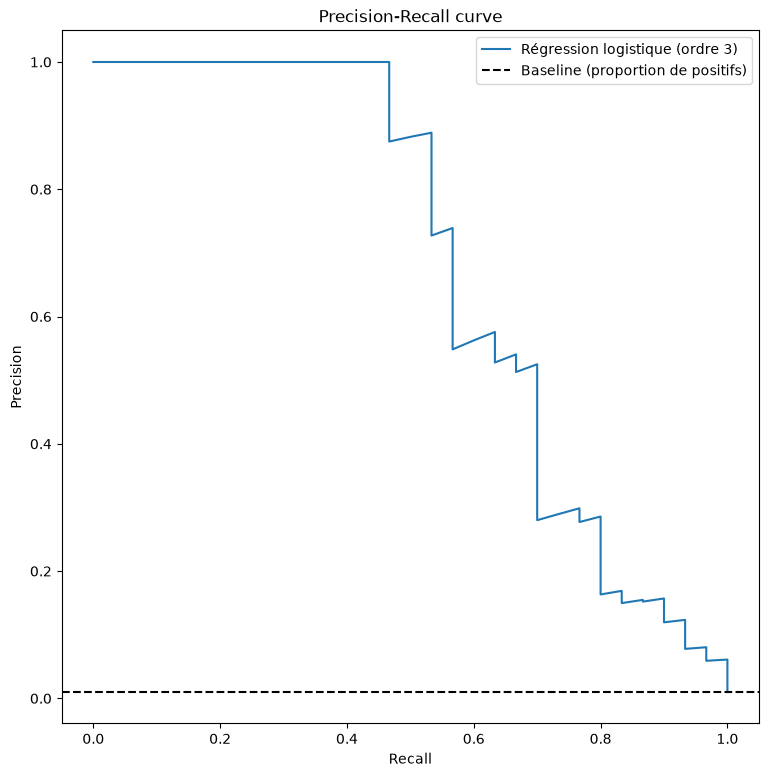

Average precision (val) = 0.6778


In [16]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision, recall, pr_thresholds = precision_recall_curve(y_val, y_val_pred_proba)

fig = plt.figure(6, figsize=(9, 9))
plt.plot(recall, precision, label='Régression logistique (ordre 3)')
plt.axhline(y_val.mean(), color='k', linestyle='--', label='Baseline (proportion de positifs)')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall curve')
plt.legend()
plt.show()

print(f'Average precision (val) = {average_precision_score(y_val, y_val_pred_proba):.4f}')

### 8 - Évaluer le F-score pour différents seuils

#### Sélection d'une valeur de beta et calcul du F-score pour différentes valeurs du seuil

Meilleur seuil (F2) = 0.13, F2 = 0.6562


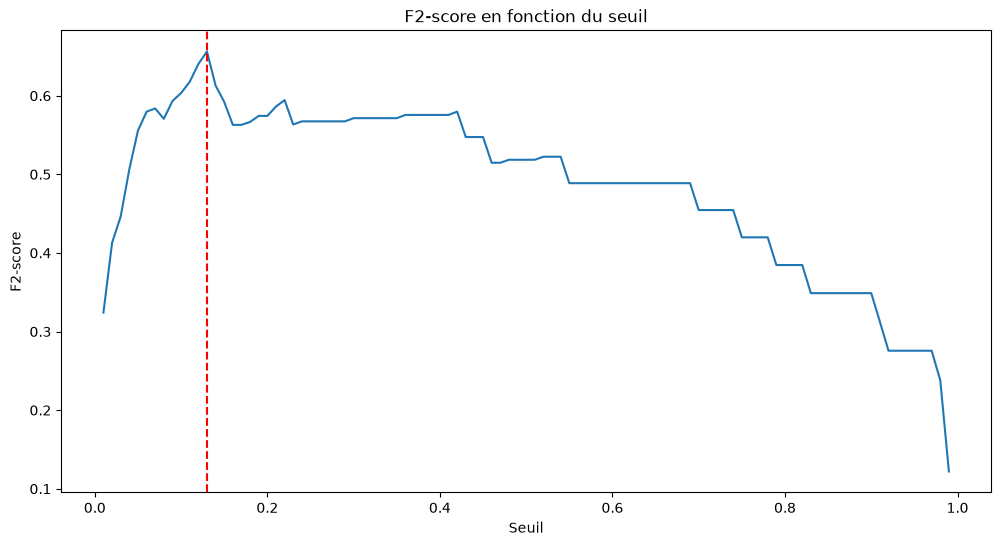

In [17]:
from sklearn.metrics import fbeta_score

# beta > 1 : on accorde plus d'importance au rappel (les faux négatifs coûtent cher)
beta = 2

seuils = np.linspace(0.01, 0.99, 99)
f_scores = [fbeta_score(y_val, (y_val_pred_proba >= s).astype(int), beta=beta, zero_division=0) for s in seuils]

best_fbeta_threshold = seuils[int(np.argmax(f_scores))]
print(f'Meilleur seuil (F{beta}) = {best_fbeta_threshold:.2f}, F{beta} = {max(f_scores):.4f}')

fig = plt.figure(7, figsize=(12, 6))
plt.plot(seuils, f_scores)
plt.axvline(best_fbeta_threshold, color='r', linestyle='--')
plt.xlabel('Seuil')
plt.ylabel(f'F{beta}-score')
plt.title(f'F{beta}-score en fonction du seuil')
plt.show()

### 9 - Calcul de la métrique d'entropie croisée

#### Calcul de l'entropie croiseé (ou log loss)

In [18]:
from sklearn.metrics import log_loss

print(f'Log loss modèle (val) = {log_loss(y_val, y_val_pred_proba):.4f}')

# Comparaison: modèle naïf qui prédit toujours la proportion de positifs de l'ensemble d'entraînement
y_val_prior = np.full(len(y_val), y_train.mean())
print(f'Log loss baseline (val) = {log_loss(y_val, y_val_prior):.4f}')

Log loss modèle (val) = 0.0210
Log loss baseline (val) = 0.0560


### 10 - Calcul de la métrique d'utilité

#### Calcul de la matrice d'utilité correspondant à la matrice de confusion précédente et avec les coûts suivants

FP: -100
FN: -10000
TP: 1000
TN: 0

Utilité (seuil = 0.5) = -146100
Utilité (seuil = 0.018) = -11900
Meilleur seuil (utilité) = 0.0175, utilité = -11900


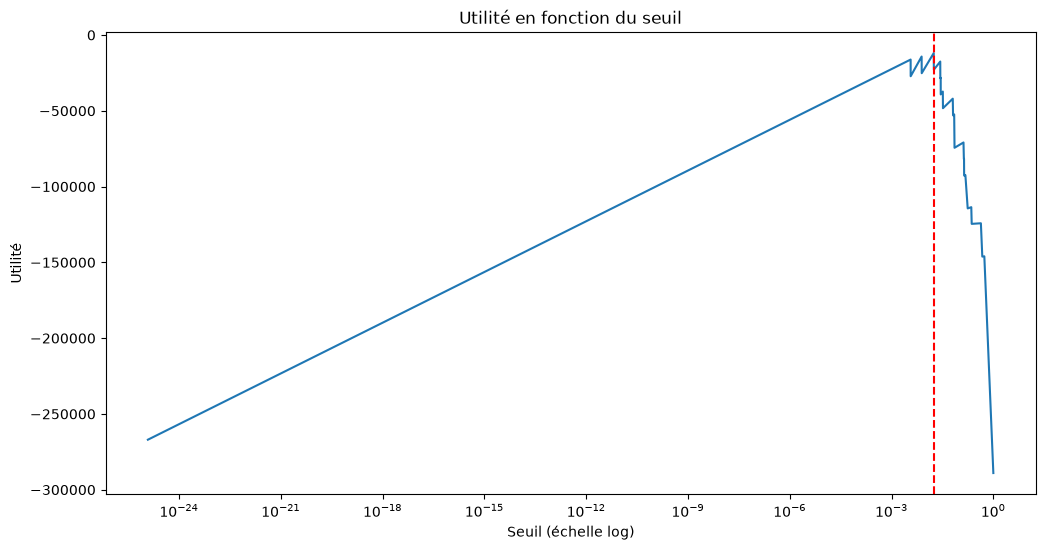

In [19]:
# Matrice d'utilité dans le même format que la matrice de confusion: [[TN, FP], [FN, TP]]
U = np.array([[0, -100],
              [-10000, 1000]])

def utilite(y_true, y_pred):
    return (confusion_matrix(y_true, y_pred) * U).sum()

print(f'Utilité (seuil = 0.5) = {utilite(y_val, y_val_pred)}')
print(f'Utilité (seuil = {selected_threshold:.3f}) = {utilite(y_val, y_val_pred_selected)}')

# Recherche du seuil qui maximise l'utilité parmi les seuils de la courbe ROC
# (le premier seuil, infini, est ignoré)
seuils_roc = thresholds[1:]
utilites = [utilite(y_val, (y_val_pred_proba >= s).astype(int)) for s in seuils_roc]
best_utility_threshold = seuils_roc[int(np.argmax(utilites))]
print(f'Meilleur seuil (utilité) = {best_utility_threshold:.4f}, utilité = {max(utilites)}')

fig = plt.figure(8, figsize=(12, 6))
plt.semilogx(seuils_roc, utilites)
plt.axvline(best_utility_threshold, color='r', linestyle='--')
plt.xlabel('Seuil (échelle log)')
plt.ylabel('Utilité')
plt.title('Utilité en fonction du seuil')
plt.show()

### Fin de l'atelier